# SymPhase tutorial 2 — convex hull and energy above hull for any number of elements

> ⚠️ The example energies in `examples/hull/*.csv` are **toy numbers** made for teaching (see `make_toy_data.py`).
> For real systems use `symphase run <elements>` (tutorial 3) or your own VASP runs.

## 1. Theory

* **Formation energy** per atom: $E_f(\mathrm{A}_x\mathrm{B}_y\dots)=\dfrac{E_{tot}-\sum_i n_i\,\mu_i^{0}}{\sum_i n_i}$ with $\mu_i^0$ the energy per atom of the most stable elemental phase.
* The **convex hull** is the lower convex envelope of all $(\text{composition},E_f)$ points; phases on it are thermodynamically stable at 0 K.
* **Energy above hull** $E_{hull}\ge 0$: energy per atom released when the phase decomposes into the hull phases at the same composition (the decomposition is given by the lever rule).
* **Stability margin** (equilibrium reaction energy) of a stable phase: how far below the hull of all *other* phases it lies (negative = robustly stable).

For $n$ elements the hull lives in an $n$-dimensional space (composition simplex × energy). SymPhase uses pymatgen's `PhaseDiagram` (Qhull) and parallelises everything that is done *per entry*.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

## 2. Binary Ni–Al

In [2]:
from symphase.hull import HullAnalysis, load_csv
h = HullAnalysis(load_csv(f"{EX}/hull/NiAl_binary.csv"))
h.print_table()


Convex hull: Al-Ni  (2 elements, 14 entries, 6 stable)
  elemental references (eV/atom): Al: -3.7500, Ni: -5.5700
  name           formula         E (eV/at)    E_form    E_hull  stable decomposition / stability margin
                                             (eV/at)  (meV/at)
  ---------------------------------------------------------------------------------------------------------------------------
  NiAl-B2        AlNi              -5.3250   -0.6650       0.0  yes    stable, margin -124.3 meV/atom
  Ni2Al3-D513    Al3Ni2            -5.0630   -0.5850       0.0  yes    stable, margin -18.0 meV/atom
  Ni3Al-L12      AlNi3             -5.5450   -0.4300       0.0  yes    stable, margin -97.5 meV/atom
  NiAl3-D011     Al3Ni             -4.6250   -0.4200       0.0  yes    stable, margin -54.4 meV/atom
  Ni-fcc         Ni                -5.5700    0.0000       0.0  yes    stable
  Al-fcc         Al                -3.7500    0.0000       0.0  yes    stable
  Ni3Al-D019     AlNi3         

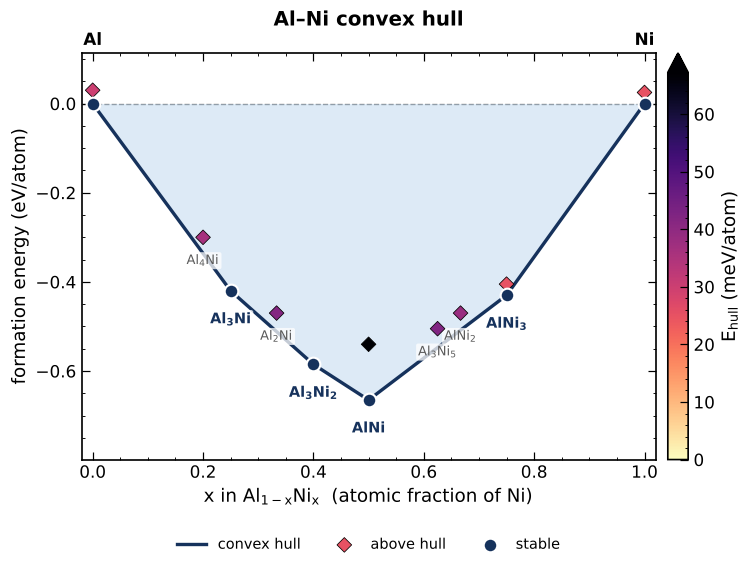

In [3]:
fig = h.plot()

Each row gives $E_f$, $E_{hull}$ and the decomposition. Ask for anything directly:

In [4]:
print("stable:", h.stable_formulas())
print("hull formation energy at Ni2Al:", round(h.hull_formation_energy("Ni2Al"), 4), "eV/atom")
print("Ni2Al decomposes into:", h.decomposition("Ni2Al"))

stable: ['Ni', 'AlNi3', 'AlNi', 'Al3Ni2', 'Al3Ni', 'Al']
hull formation energy at Ni2Al: -0.5083 eV/atom
Ni2Al decomposes into: {'AlNi3': np.float64(0.6666666666666665), 'AlNi': np.float64(0.3333333333333335)}


## 3. Ternary Ti–Ni–Sn (half-Heusler TiNiSn, full-Heusler TiNi₂Sn)

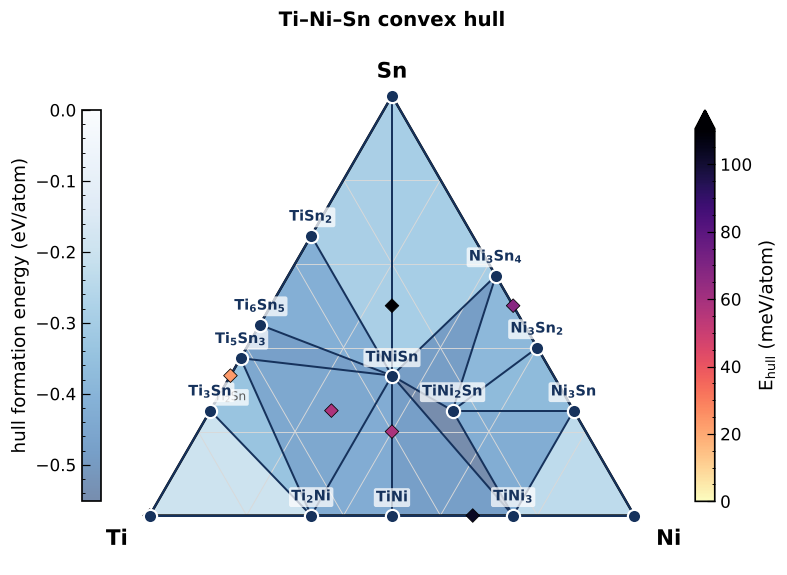

In [5]:
h3 = HullAnalysis(load_csv(f"{EX}/hull/TiNiSn_ternary.csv"))
fig = h3.plot()

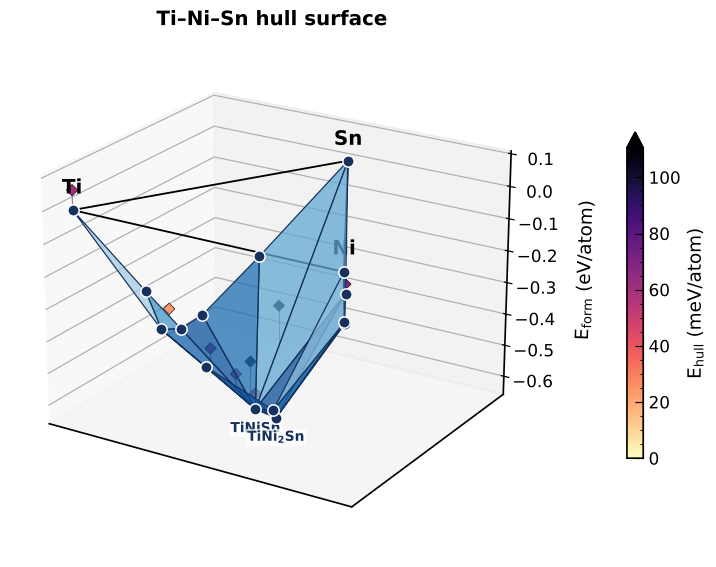

In [6]:
from symphase import hull_plots as hp
fig = hp.plot_ternary_surface(h3)

Shaded triangles are the hull facets (three-phase regions), lines are tie-lines (two-phase regions).
The 3D view shows the hull as a surface $E_f(x,y)$; metastable phases float above it.

### Pseudo-binary slice
Cut the hull along the line TiNiSn → TiNi₂Sn (the half-/full-Heusler line):

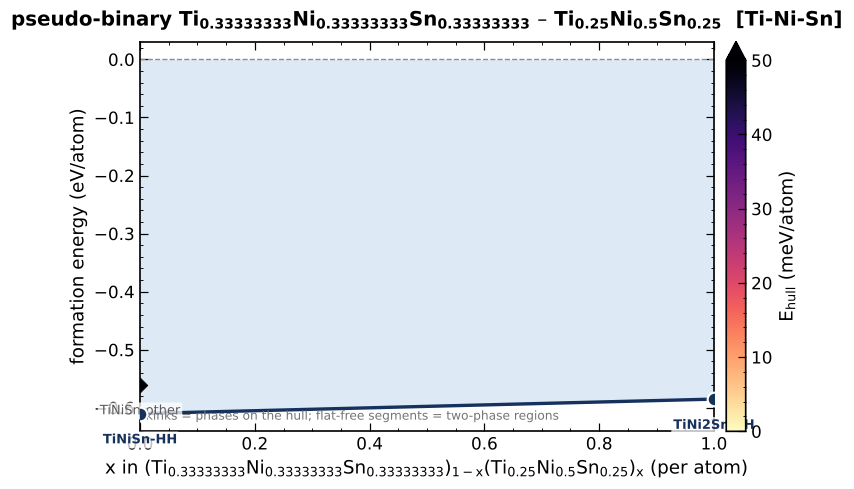

In [7]:
fig = hp.plot_pseudo_binary(h3, 'TiNiSn', 'TiNi2Sn')

## 4. Quaternary Ti–Zr–Ni–Sn

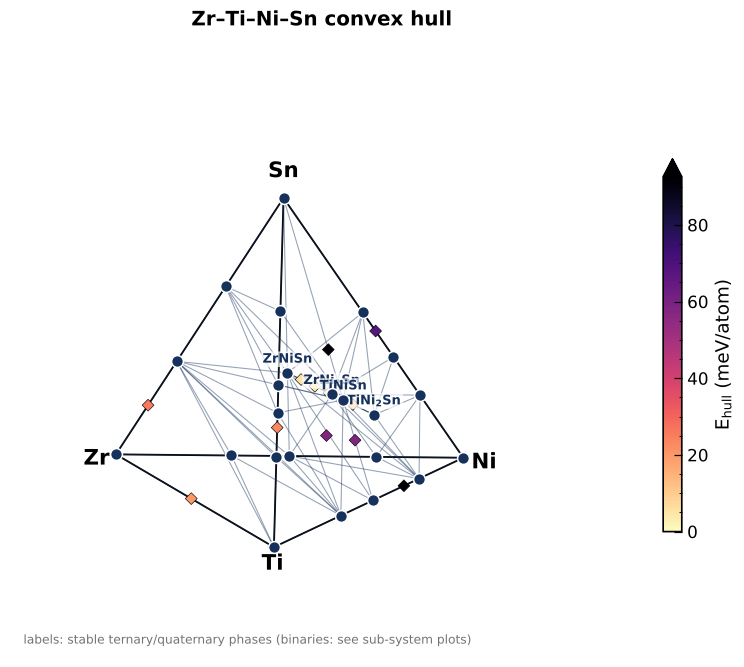

In [8]:
h4 = HullAnalysis(load_csv(f"{EX}/hull/TiZrNiSn_quaternary.csv"))
fig = h4.plot()

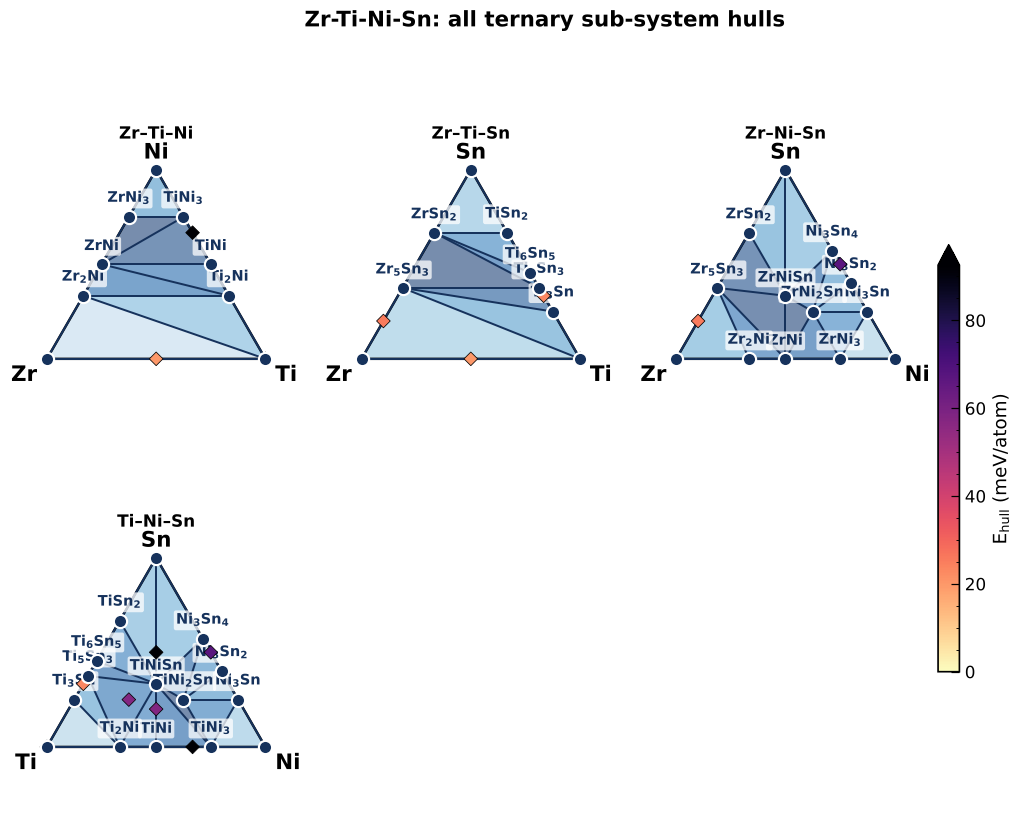

In [9]:
fig = hp.plot_subsystems(h4, order=3)

## 5. Five components Ti–Zr–Hf–Ni–Sn (high-entropy half-Heusler)

Beyond four elements a single picture is impossible; SymPhase gives (i) the grid of all binary sub-hulls,
(ii) $E_{hull}$ bars, (iii) pseudo-binary slices between any compositions.

Hf-Zr-Ti-Ni-Sn | entries: 51 | stable: 32


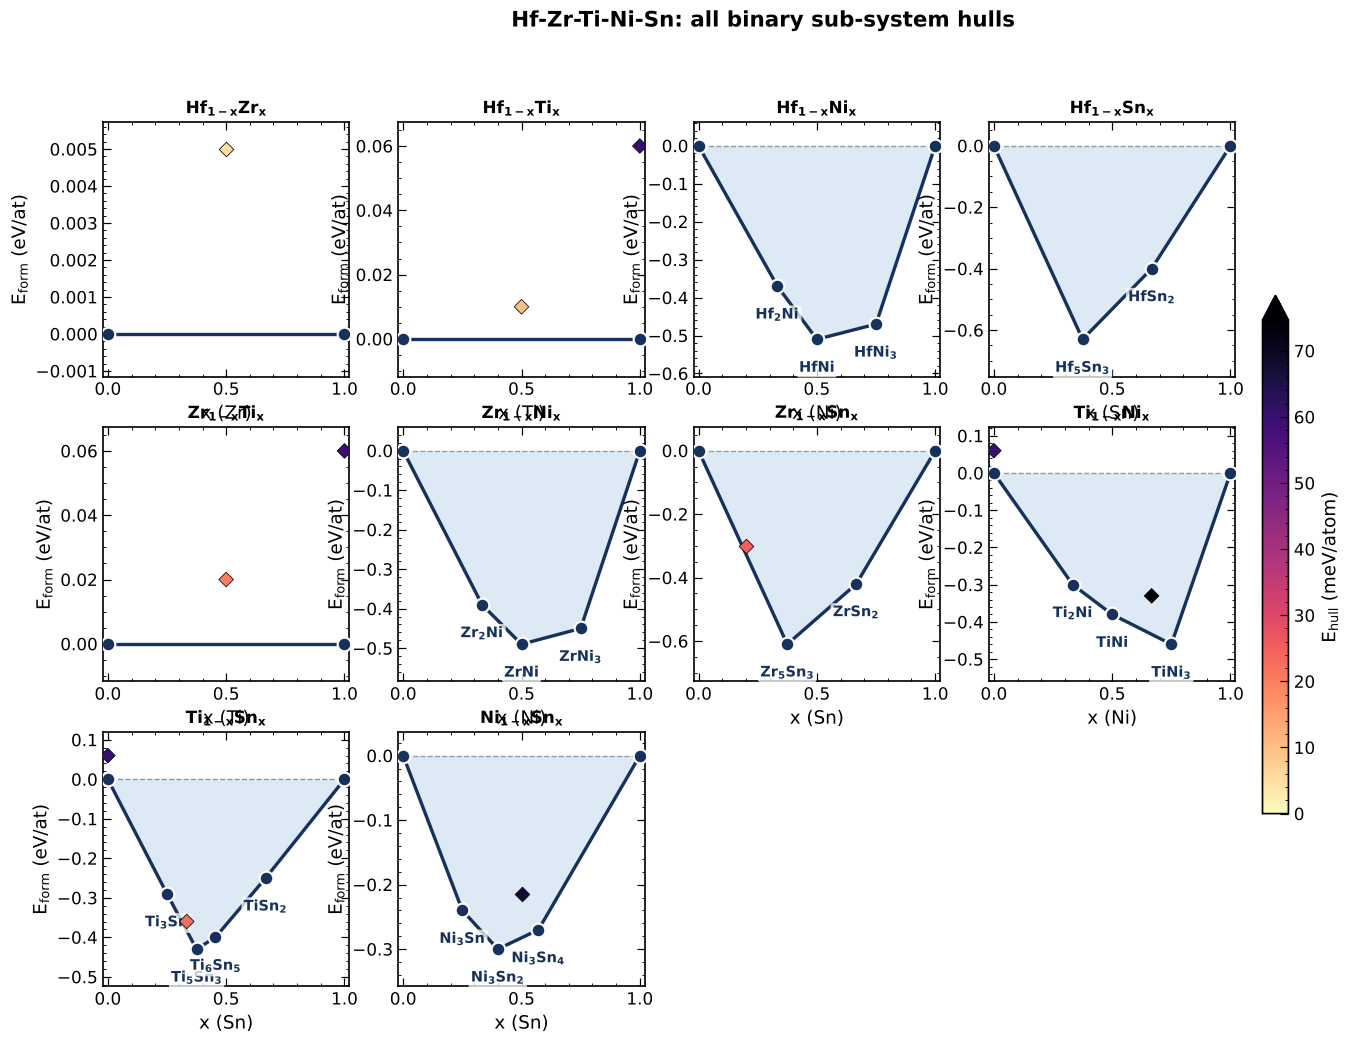

In [10]:
h5 = HullAnalysis(load_csv(f"{EX}/hull/TiZrHfNiSn_5component.csv"))
print(h5.chemsys, "| entries:", len(h5.entries), "| stable:", len(h5.pd.stable_entries))
fig = h5.plot()   # grid of binary sub-system hulls

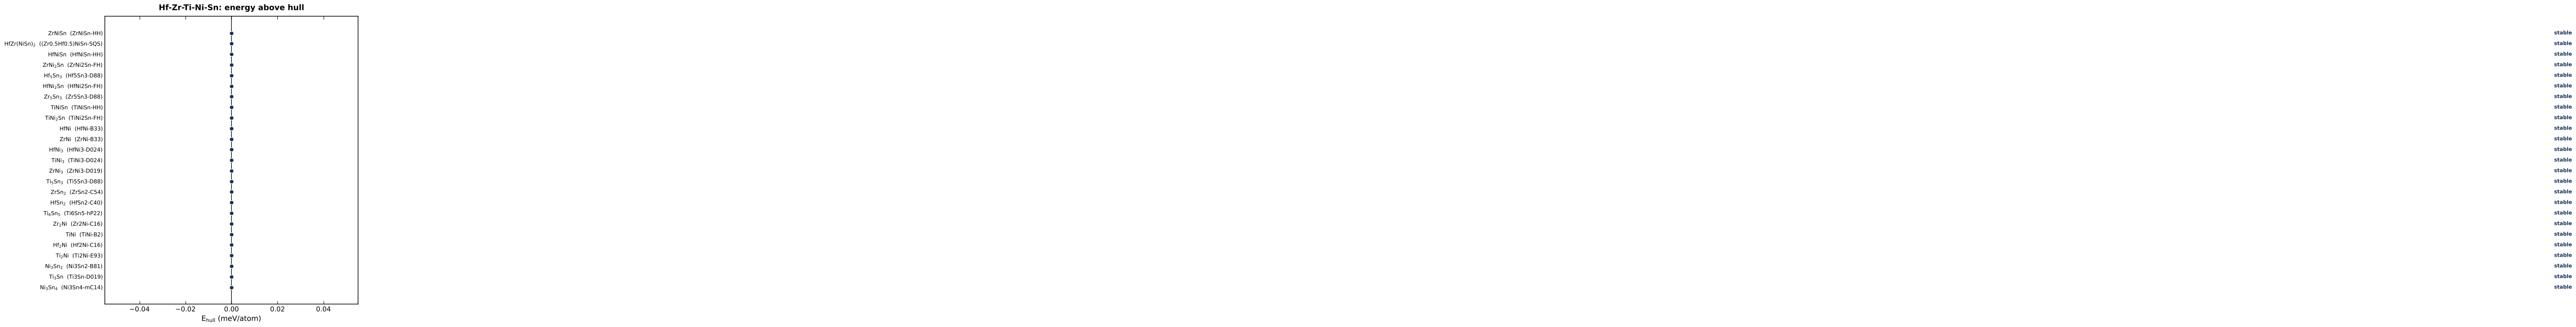

In [11]:
fig = hp.plot_ehull_bar(h5, max_rows=25)

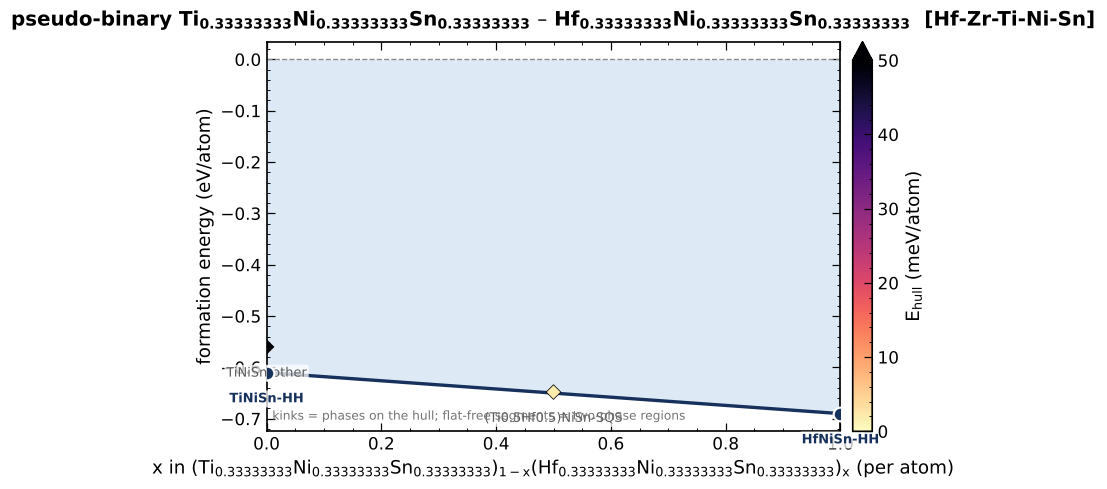

In [12]:
fig = hp.plot_pseudo_binary(h5, 'TiNiSn', 'HfNiSn')

## 6. Screening new candidates (not added to the hull)

`evaluate` / `evaluate_many` compute $E_{hull}$ of hypothetical compounds against an existing hull — in parallel.

In [13]:
from symphase.hull import make_entry
from pymatgen.core import Composition
# hypothetical energies: hull energy at that composition + an offset (meV/atom)
def toy(formula, offset_meV, name):
    e_hull = h5.pd.get_hull_energy_per_atom(Composition(formula))
    return make_entry(formula, e_hull + offset_meV / 1000, per_atom=True, name=name)
cands = [toy("TiZrHfNi3Sn3", 1.5, "HE-HH new SQS"),
         toy("Ti2ZrNi3Sn3", 8.0, "Ti-rich HE-HH"),
         toy("TiZrNi2Sn3", -12.0, "new Sn-rich phase?")]
for r in h5.evaluate_many(cands):
    print(f"{r['name']:<12s} E_hull = {1000*r['e_hull']:6.1f} meV/atom -> {r['decomposition']}")

HE-HH new SQS E_hull =    1.5 meV/atom -> 0.667 HfZr(NiSn)2 + 0.333 TiNiSn
Ti-rich HE-HH E_hull =    8.0 meV/atom -> 0.667 TiNiSn + 0.333 ZrNiSn
new Sn-rich phase? E_hull =  -12.0 meV/atom -> 0.429 TiNiSn + 0.429 ZrNiSn + 0.143 Sn


## 7. Parallel performance

Every per-entry quantity (E_hull, decomposition, stability margin), candidate screening, VASP-folder parsing and
pseudo-binary hull points run on all cores (`nproc=-1`, honours `SLURM_CPUS_PER_TASK`) or across nodes with MPI.
A synthetic 6-element system with 3000 random entries:

In [14]:
import time, numpy as np
from pymatgen.core import Composition
rng = np.random.default_rng(0); els = ["Ti", "Zr", "Hf", "Ni", "Sn", "Co"]
E = [make_entry(e, 0.0) for e in els]
for k in range(3000):
    n = rng.integers(2, 5); sub = rng.choice(els, n, replace=False); c = rng.integers(1, 5, n)
    f = "".join(f"{a}{b}" for a, b in zip(sub, c))
    E.append(make_entry(f, Composition(f).num_atoms * rng.normal(-0.35, 0.2), name=f"r{k}"))
for n in (1, -1):
    hb = HullAnalysis(E, nproc=n); t = time.time(); hb.table()
    print(f"nproc={n:>2}: {time.time()-t:.2f} s for {len(E)} entries ({len(hb.pd.stable_entries)} stable)")

nproc= 1: 0.28 s for 3006 entries (78 stable)


nproc=-1: 0.19 s for 3006 entries (78 stable)


(The sandbox that built this notebook has only 2 cores; on a 40-core Ibex node the speed-up for large systems is much larger.)

## 8. Command line

```bash
symphase hull --csv energies.csv --plot hull.png --bar
symphase hull --scan calcs/ -n 40                     # every VASP run below calcs/
symphase hull --csv refs.csv --screen candidates.csv  # high-throughput screening
symphase hull --csv data.csv --slice TiNiSn HfNiSn --subsystems 3
srun -n 160 python -m symphase hull --scan calcs/ --screen big.csv   # MPI, 4 nodes
```
CSV format: `formula,energy[,energy_type,name,structure]` (energy per formula as written, or `energy_type=per_atom`).

Your own VASP runs:

In [15]:
from symphase.hull import scan_vasp
hv = HullAnalysis(scan_vasp(f"{EX}/hull/vasp_runs_NiAl"))
print(len(hv.entries), "runs,", len(hv.pd.stable_entries), "stable:", hv.stable_formulas())

14 runs, 6 stable: ['Ni', 'AlNi3', 'AlNi', 'Al3Ni2', 'Al3Ni', 'Al']


Continue with **03_tutorial_automatic_workflow.ipynb** and **05_quiz_convex_hull.ipynb**.